In [16]:
# Cell 1: Imports and setup
import os
import re
import string
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc
)

import joblib
from wordcloud import WordCloud

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# Download NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

# Output folders
os.makedirs("../models", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

print("Setup complete.")

Setup complete.


In [17]:
# Cell 2: Load dataset
df = pd.read_csv("../data/steam_reviews.csv")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Shape: (2000, 2)

Columns: ['review', 'sentiment']

First 5 rows:


,review,sentiment
0,"Wow, Addictive gameplay loop with lots of cont...",positive
1,"Wow, Great modding support and active community.",positive
2,"Wow, The devs abandoned this game after launch.",negative
3,"Dude, I can't stop playing. Truly a masterpiece.",positive
4,"Honestly, The combat system is deep and reward...",positive


Missing values:
review       0
sentiment    0
dtype: int64

Class distribution:
sentiment
positive    1000
negative    1000
Name: count, dtype: int64


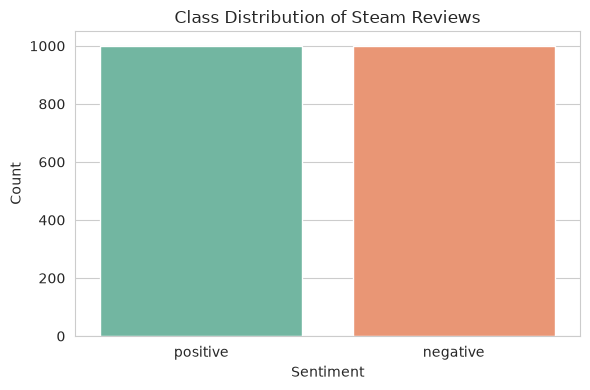

In [18]:
# Cell 3: Basic EDA
print("Missing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["sentiment"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment", palette="Set2")
plt.title("Class Distribution of Steam Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("../outputs/class_distribution.png", dpi=150)
plt.show()

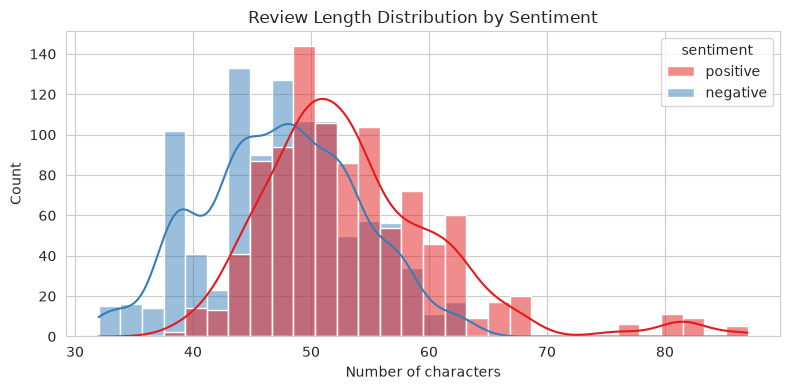

            count    mean       std   min   25%   50%   75%   max
sentiment                                                        
negative   1000.0  47.435  6.507544  32.0  43.0  48.0  52.0  63.0
positive   1000.0  53.562  7.842937  38.0  48.0  52.0  58.0  87.0


In [19]:
# Cell 4: Review length
df["review_length"] = df["review"].astype(str).apply(len)

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="review_length", hue="sentiment",
             bins=30, kde=True, palette="Set1")
plt.title("Review Length Distribution by Sentiment")
plt.xlabel("Number of characters")
plt.tight_layout()
plt.savefig("../outputs/review_length_hist.png", dpi=150)
plt.show()

print(df.groupby("sentiment")["review_length"].describe())

In [20]:
# Cell 5: Text preprocessing
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", "", text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens
              if w not in stop_words and len(w) > 2]
    return " ".join(tokens)

df["clean_review"] = df["review"].apply(clean_text)

print("Original:")
print(df["review"].iloc[0])
print("\nCleaned:")
print(df["clean_review"].iloc[0])

Original:
Wow, Addictive gameplay loop with lots of content.

Cleaned:
wow addictive gameplay loop lot content


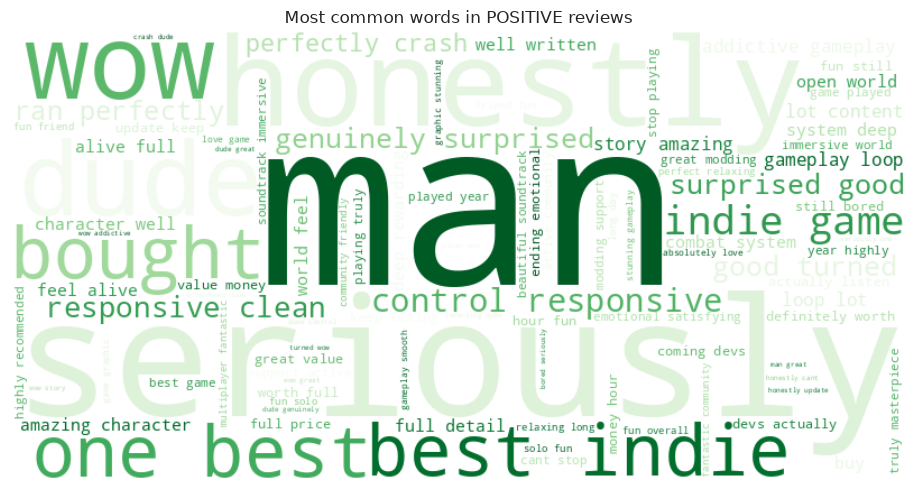

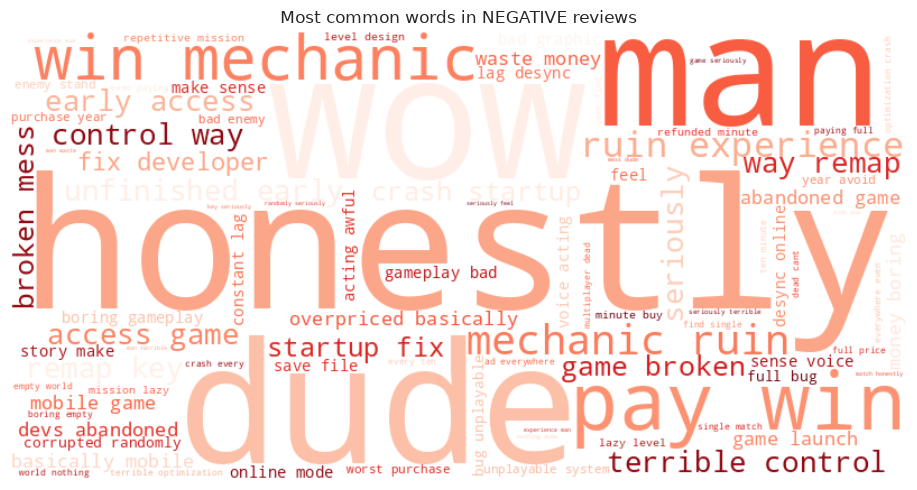

In [21]:
# Cell 6: Word clouds
pos_text = " ".join(df[df["sentiment"] == "positive"]["clean_review"])
neg_text = " ".join(df[df["sentiment"] == "negative"]["clean_review"])

wc_pos = WordCloud(width=800, height=400, background_color="white",
                   colormap="Greens").generate(pos_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc_pos, interpolation="bilinear")
plt.axis("off")
plt.title("Most common words in POSITIVE reviews")
plt.tight_layout()
plt.savefig("../outputs/wordcloud_positive.png", dpi=150)
plt.show()

wc_neg = WordCloud(width=800, height=400, background_color="white",
                   colormap="Reds").generate(neg_text)
plt.figure(figsize=(10, 5))
plt.imshow(wc_neg, interpolation="bilinear")
plt.axis("off")
plt.title("Most common words in NEGATIVE reviews")
plt.tight_layout()
plt.savefig("../outputs/wordcloud_negative.png", dpi=150)
plt.show()

In [22]:
# Cell 7: Labels and split
df["label"] = df["sentiment"].map({"negative": 0, "positive": 1})

X_text = df["clean_review"]
y = df["label"]

X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train_txt))
print("Test size :", len(X_test_txt))

Train size: 1600
Test size : 400


In [23]:
# Cell 8: TF-IDF
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)

X_train = tfidf.fit_transform(X_train_txt)
X_test  = tfidf.transform(X_test_txt)

print("TF-IDF train shape:", X_train.shape)
print("TF-IDF test shape :", X_test.shape)

TF-IDF train shape: (1600, 490)
TF-IDF test shape : (400, 490)


In [24]:
# Cell 9: Train three models
nb = MultinomialNB()
nb.fit(X_train, y_train)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

svm_base = LinearSVC(random_state=42)
svm = CalibratedClassifierCV(svm_base, cv=3)
svm.fit(X_train, y_train)

print("All models trained.")

All models trained.


In [25]:
# Cell 10: Evaluation helper
def evaluate_model(name, model, X_test, y_test, save_cm=True):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"===== {name} =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"]))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"],
                yticklabels=["negative", "positive"])
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    if save_cm:
        plt.savefig(f"../outputs/confusion_matrix_{name.lower().replace(' ', '_')}.png", dpi=150)
    plt.show()

    return {"model": name, "accuracy": acc, "precision": prec,
            "recall": rec, "f1": f1, "y_pred": y_pred}

===== Naive Bayes =====
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       200
    positive       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



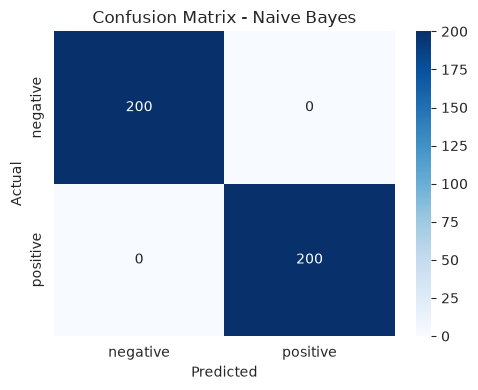

===== Logistic Regression =====
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       200
    positive       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



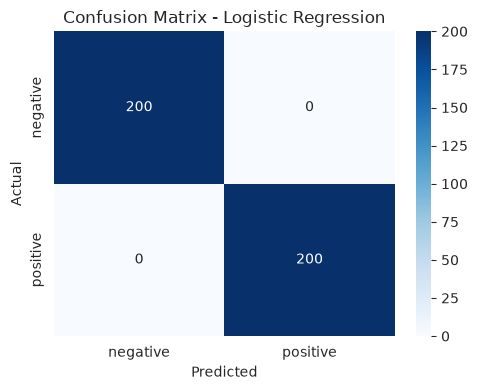

===== SVM =====
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       200
    positive       1.00      1.00      1.00       200

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



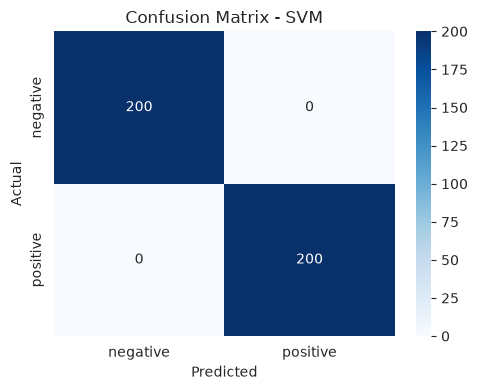

In [26]:
# Cell 11: Run evaluations
results_nb  = evaluate_model("Naive Bayes", nb,  X_test, y_test)
results_lr  = evaluate_model("Logistic Regression", lr, X_test, y_test)
results_svm = evaluate_model("SVM", svm, X_test, y_test)

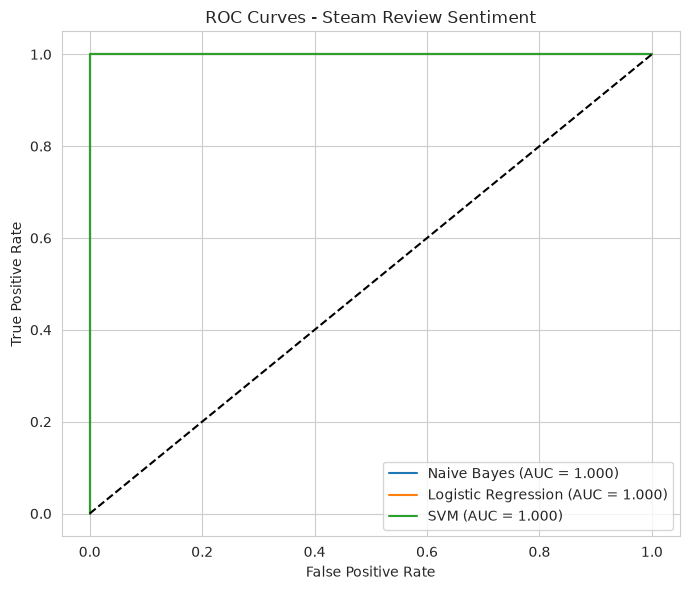

In [27]:
# Cell 12: ROC curves
plt.figure(figsize=(7, 6))

for name, model in [("Naive Bayes", nb),
                    ("Logistic Regression", lr),
                    ("SVM", svm)]:
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Steam Review Sentiment")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../outputs/roc_curves.png", dpi=150)
plt.show()

,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Logistic Regression,1.0,1.0,1.0,1.0
2,SVM,1.0,1.0,1.0,1.0


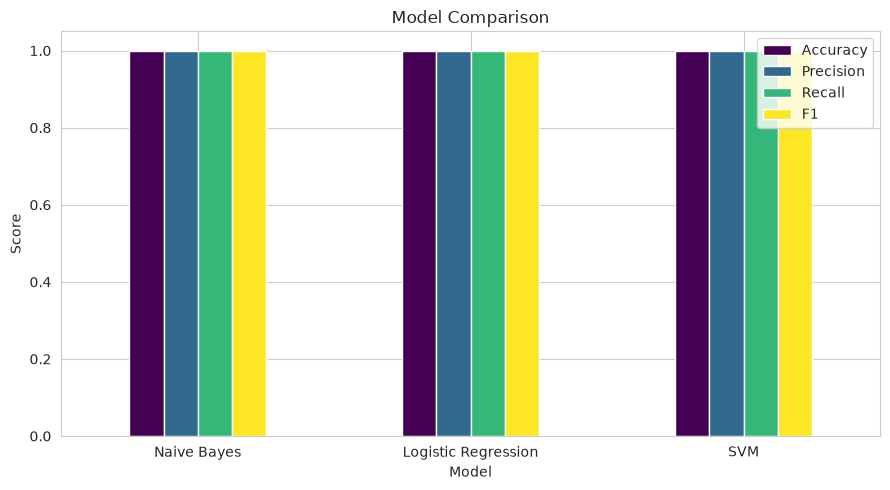

In [28]:
# Cell 13: Compare models
comparison = pd.DataFrame([
    {"Model": results_nb["model"],  "Accuracy": results_nb["accuracy"],
     "Precision": results_nb["precision"], "Recall": results_nb["recall"], "F1": results_nb["f1"]},
    {"Model": results_lr["model"],  "Accuracy": results_lr["accuracy"],
     "Precision": results_lr["precision"], "Recall": results_lr["recall"], "F1": results_lr["f1"]},
    {"Model": results_svm["model"], "Accuracy": results_svm["accuracy"],
     "Precision": results_svm["precision"], "Recall": results_svm["recall"], "F1": results_svm["f1"]},
])

display(comparison)

comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]] \
          .plot(kind="bar", figsize=(9, 5), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../outputs/model_comparison.png", dpi=150)
plt.show()

In [29]:
# Cell 14: Save models
joblib.dump(nb,    "../models/naive_bayes_model.pkl")
joblib.dump(lr,    "../models/logistic_regression_model.pkl")
joblib.dump(svm,   "../models/svm_model.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Models and vectorizer saved to ../models/")

Models and vectorizer saved to ../models/


In [30]:
# Cell 15: Live prediction
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")
loaded_lr    = joblib.load("../models/logistic_regression_model.pkl")

def predict_sentiment(review_text):
    cleaned = clean_text(review_text)
    vec = loaded_tfidf.transform([cleaned])
    pred = loaded_lr.predict(vec)[0]
    prob = loaded_lr.predict_proba(vec)[0]
    label = "POSITIVE ✅" if pred == 1 else "NEGATIVE ❌"
    print(f"Review: {review_text}")
    print(f"Prediction: {label}")
    print(f"Confidence: {prob[pred]*100:.2f}%")
    print("-" * 60)

predict_sentiment("This game is absolutely amazing, I love it!")
predict_sentiment("Worst game ever, crashes all the time.")
predict_sentiment("Not bad, but the story could be better.")
predict_sentiment("Total waste of money, do not buy.")

Review: This game is absolutely amazing, I love it!
Prediction: POSITIVE ✅
Confidence: 73.96%
------------------------------------------------------------
Review: Worst game ever, crashes all the time.
Prediction: NEGATIVE ❌
Confidence: 52.15%
------------------------------------------------------------
Review: Not bad, but the story could be better.
Prediction: NEGATIVE ❌
Confidence: 76.20%
------------------------------------------------------------
Review: Total waste of money, do not buy.
Prediction: NEGATIVE ❌
Confidence: 75.32%
------------------------------------------------------------
